<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · One character budget is not a token budget

**What changes when we count the same text with a different encoding?**
We will use SQL to compare Unicode code points, UTF-8 bytes and BPE tokens, then
inspect token IDs and a truncation boundary. The worker processes the actual
strings; Python presents the returned measurements.

These are small, original teaching examples, not a language-wide benchmark.
Counts describe ordinary text under two explicit encodings. They do not include
chat wrappers, tool definitions, images or other API usage overhead.

## Choose the encoding to inspect

`ENCODING` accepts **`cl100k_base`** or **`o200k_base`**. The default is
`cl100k_base`; the final experiment selects `o200k_base`. Both are always included
in the reference comparison. This parameter chooses the detailed table, chart
outline and ratios. Restart the kernel and run all after editing.

In [1]:
ENCODING = "cl100k_base"

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from notebook_support import finish, prose, theme

if ENCODING not in {"cl100k_base", "o200k_base"}:
    raise ValueError("ENCODING must be cl100k_base or o200k_base.")
ENCODING_COLORS = {"cl100k_base": "#456fba", "o200k_base": "#267358"}
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/vgi-tiktoken/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/vgi-tiktoken/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/vgi-tiktoken/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-tiktoken/notebooks/pyproject.toml.

## Connect to the released tokenizer

The literal location downloads and verifies the **v0.4.1** native release for
this platform and caches it. No local Rust build is needed. The notebook locks
Haybarn **2.0.0rc11**; the worker bundles its encoding vocabularies. Initial
installation needs network access; tokenization itself uses local text only.

We pass canonical encoding names explicitly. That keeps this investigation
independent of changing model-name mappings.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tokens' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-tiktoken@v0.4.1');
SELECT 'cl100k_base' AS encoding, tokens.main.count_tokens('hello world', 'cl100k_base') AS tokens
UNION ALL
SELECT 'o200k_base', tokens.main.count_tokens('hello world', 'o200k_base');

,encoding,tokens
0,cl100k_base,2
1,o200k_base,2


## Keep the exact input strings visible

SQL constructs eleven fixed examples. The five sentences convey a similar idea
but are not a controlled translation benchmark. JSON, identifiers and digits
provide other text shapes. The indented English sentence preserves four spaces.

The last two rows look similar: one uses precomposed **é**, the other **e + a
combining acute accent**. We perform no normalization. `length(text)` counts
Unicode code points, which can differ from visible characters; `octet_length(encode(text))`
counts UTF-8 bytes. Neither is a token count.

In [5]:
%%sql
CREATE OR REPLACE TABLE samples AS
SELECT * FROM (VALUES
 (1, 'English sentence', 'The river is quiet today.'),
 (2, 'French sentence', 'La rivière est calme aujourd''hui.'),
 (3, 'Japanese sentence', '今日は川が静かです。'),
 (4, 'Mandarin sentence', '今天河边很安静。'),
 (5, 'Russian sentence', 'Сегодня у реки тихо.'),
 (6, 'JSON record', '{"station":"river","flow":12.5,"ok":true}'),
 (7, 'Identifier', 'riverFlowRate_mm_per_hour'),
 (8, 'Digits', '123456789012345678901234567890'),
 (9, 'Indented English', '    The river is quiet today.'),
 (10, 'Accent: precomposed', 'café'),
 (11, 'Accent: combining', 'cafe' || chr(769))
) t(sample_id, label, text);
SELECT sample_id, label, text, length(text) AS code_points,
       octet_length(encode(text)) AS utf8_bytes
FROM samples ORDER BY sample_id;

,sample_id,label,text,code_points,utf8_bytes
0,1,English sentence,The river is quiet today.,25,25
1,2,French sentence,La rivière est calme aujourd'hui.,33,34
2,3,Japanese sentence,今日は川が静かです。,10,30
3,4,Mandarin sentence,今天河边很安静。,8,24
4,5,Russian sentence,Сегодня у реки тихо.,20,36
5,6,JSON record,"{""station"":""river"",""flow"":12.5,""ok"":true}",41,41
6,7,Identifier,riverFlowRate_mm_per_hour,25,25
7,8,Digits,123456789012345678901234567890,30,30
8,9,Indented English,The river is quiet today.,29,29
9,10,Accent: precomposed,café,4,5


## Count with both encodings, then check the token lists

We materialize the worker outputs once per string and encoding. The first check
compares each count with the length of its returned token-ID list. The remaining
controls distinguish empty text (zero), missing text (NULL) and an unknown
encoding (NULL). Turning either NULL into zero would hide missing metadata.

In [6]:
%%sql
CREATE OR REPLACE TABLE measurements AS
SELECT sample_id, label, text, encoding, length(text) AS code_points,
       octet_length(encode(text)) AS utf8_bytes,
       tokens.main.count_tokens(text, encoding) AS token_count,
       tokens.main.tokenize(text, encoding) AS token_ids
FROM samples CROSS JOIN (VALUES ('cl100k_base'), ('o200k_base')) e(encoding);
CREATE OR REPLACE TABLE controls AS
SELECT tokens.main.count_tokens('', '{{ ENCODING }}') AS empty_count,
       tokens.main.count_tokens(NULL, '{{ ENCODING }}') AS missing_count,
       tokens.main.count_tokens('hello', 'not_an_encoding') AS unknown_count;
SELECT * FROM controls;

,empty_count,missing_count,unknown_count
0,0,<NA>,<NA>


In [7]:
%%sql checks <<
SELECT 'Count agrees with token-list length' AS check_name,
       count(*) FILTER (WHERE token_count IS DISTINCT FROM len(token_ids)) AS violations FROM measurements
UNION ALL
SELECT 'Nonempty examples have positive counts',
       count(*) FILTER (WHERE token_count IS NULL OR token_count <= 0) FROM measurements
UNION ALL
SELECT 'One result per sample and encoding', count(*) FROM (
 SELECT sample_id, encoding FROM measurements GROUP BY sample_id, encoding HAVING count(*) <> 1
)
UNION ALL
SELECT 'Both encodings cover every input',
       abs(count(*) - 2 * (SELECT count(*) FROM samples)) FROM measurements
UNION ALL
SELECT 'Empty text is zero; missing or unknown stays NULL',
       count(*) FILTER (WHERE empty_count IS DISTINCT FROM 0 OR missing_count IS NOT NULL OR unknown_count IS NOT NULL)
FROM controls;

In [8]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), (
    "Token accounting or missing-value behavior changed."
)
prose(
    f"All **{len(checks)} checks pass**. Counts and token-list lengths agree; missing metadata stays distinguishable from an empty input. We can now compare the measured encodings on the same strings."
)

,check_name,violations
0,Count agrees with token-list length,0
1,Nonempty examples have positive counts,0
2,One result per sample and encoding,0
3,Both encodings cover every input,0
4,Empty text is zero; missing or unknown stays NULL,0


All **5 checks pass**. Counts and token-list lengths agree; missing metadata stays distinguishable from an empty input. We can now compare the measured encodings on the same strings.

In [9]:
%%sql comparison <<
SELECT sample_id, label,
       max(token_count) FILTER (WHERE encoding = 'cl100k_base') AS cl100k_tokens,
       max(token_count) FILTER (WHERE encoding = 'o200k_base') AS o200k_tokens
FROM measurements GROUP BY sample_id, label ORDER BY sample_id;

## An encoding change affects different strings differently

Each paired row is the **same input text**. Bar labels give exact token counts;
the dark outline marks the selected encoding. The fixed sample order groups
sentences, structured text and the accent pair. A shorter token sequence here
does not establish model quality or efficiency across a whole language.

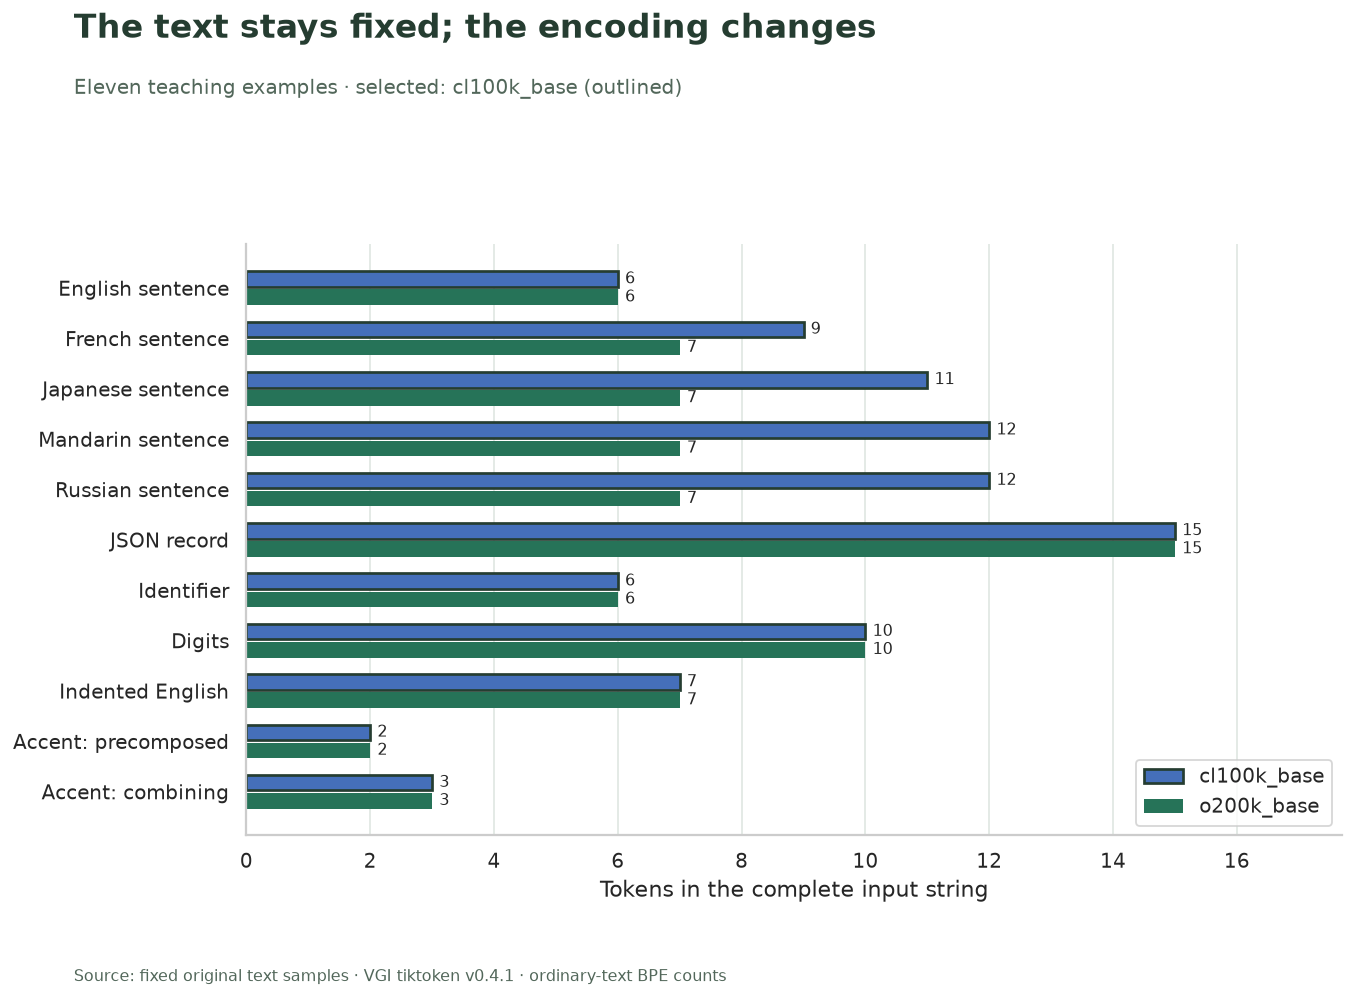

On these **11 fixed strings**, o200k_base uses fewer tokens in **4**, the same number in **7**, and more in **0**. These are per-string comparisons, not a general ranking of encodings.

In [10]:
comparison = globals()["comparison"]
y = np.arange(len(comparison))
fig, ax = plt.subplots(figsize=(10.8, 7.8))
for offset, (encoding, column) in zip(
    (-0.18, 0.18),
    (("cl100k_base", "cl100k_tokens"), ("o200k_base", "o200k_tokens")),
    strict=True,
):
    bars = ax.barh(
        y + offset,
        comparison[column],
        height=0.31,
        color=ENCODING_COLORS[encoding],
        edgecolor="#253d31" if encoding == ENCODING else "none",
        linewidth=1.5,
        label=encoding,
    )
    ax.bar_label(bars, padding=4, fontsize=9)
ax.set(
    yticks=y,
    yticklabels=comparison.label,
    xlabel="Tokens in the complete input string",
    ylabel="",
)
ax.invert_yaxis()
ax.set_xlim(0, comparison[["cl100k_tokens", "o200k_tokens"]].to_numpy().max() * 1.18)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=True)
finish(
    fig,
    "The text stays fixed; the encoding changes",
    f"Eleven teaching examples · selected: {ENCODING} (outlined)",
    f"counts-{ENCODING}.png",
)
fewer = int((comparison.o200k_tokens < comparison.cl100k_tokens).sum())
equal = int((comparison.o200k_tokens == comparison.cl100k_tokens).sum())
more = int((comparison.o200k_tokens > comparison.cl100k_tokens).sum())
prose(
    f"On these **{len(comparison)} fixed strings**, o200k_base uses fewer tokens in **{fewer}**, the same number in **{equal}**, and more in **{more}**. These are per-string comparisons, not a general ranking of encodings."
)

## Ratios need both a unit and an encoding

For the selected encoding, SQL divides code points and UTF-8 bytes by the exact
token count. The panels have **independent scales and different units**. Values
vary with these strings' content and representation; a single character-to-token
multiplier would erase that variation.

In [11]:
%%sql selected <<
SELECT sample_id, label, code_points, utf8_bytes, token_count,
       code_points::DOUBLE / token_count AS code_points_per_token,
       utf8_bytes::DOUBLE / token_count AS bytes_per_token
FROM measurements WHERE encoding = '{{ ENCODING }}' ORDER BY sample_id;

,sample_id,label,code_points,utf8_bytes,token_count,code_points_per_token,bytes_per_token
0,1,English sentence,25,25,6,4.166667,4.166667
1,2,French sentence,33,34,9,3.666667,3.777778
2,3,Japanese sentence,10,30,11,0.909091,2.727273
3,4,Mandarin sentence,8,24,12,0.666667,2.000000
4,5,Russian sentence,20,36,12,1.666667,3.000000
5,6,JSON record,41,41,15,2.733333,2.733333
6,7,Identifier,25,25,6,4.166667,4.166667
7,8,Digits,30,30,10,3.000000,3.000000
8,9,Indented English,29,29,7,4.142857,4.142857
9,10,Accent: precomposed,4,5,2,2.000000,2.500000


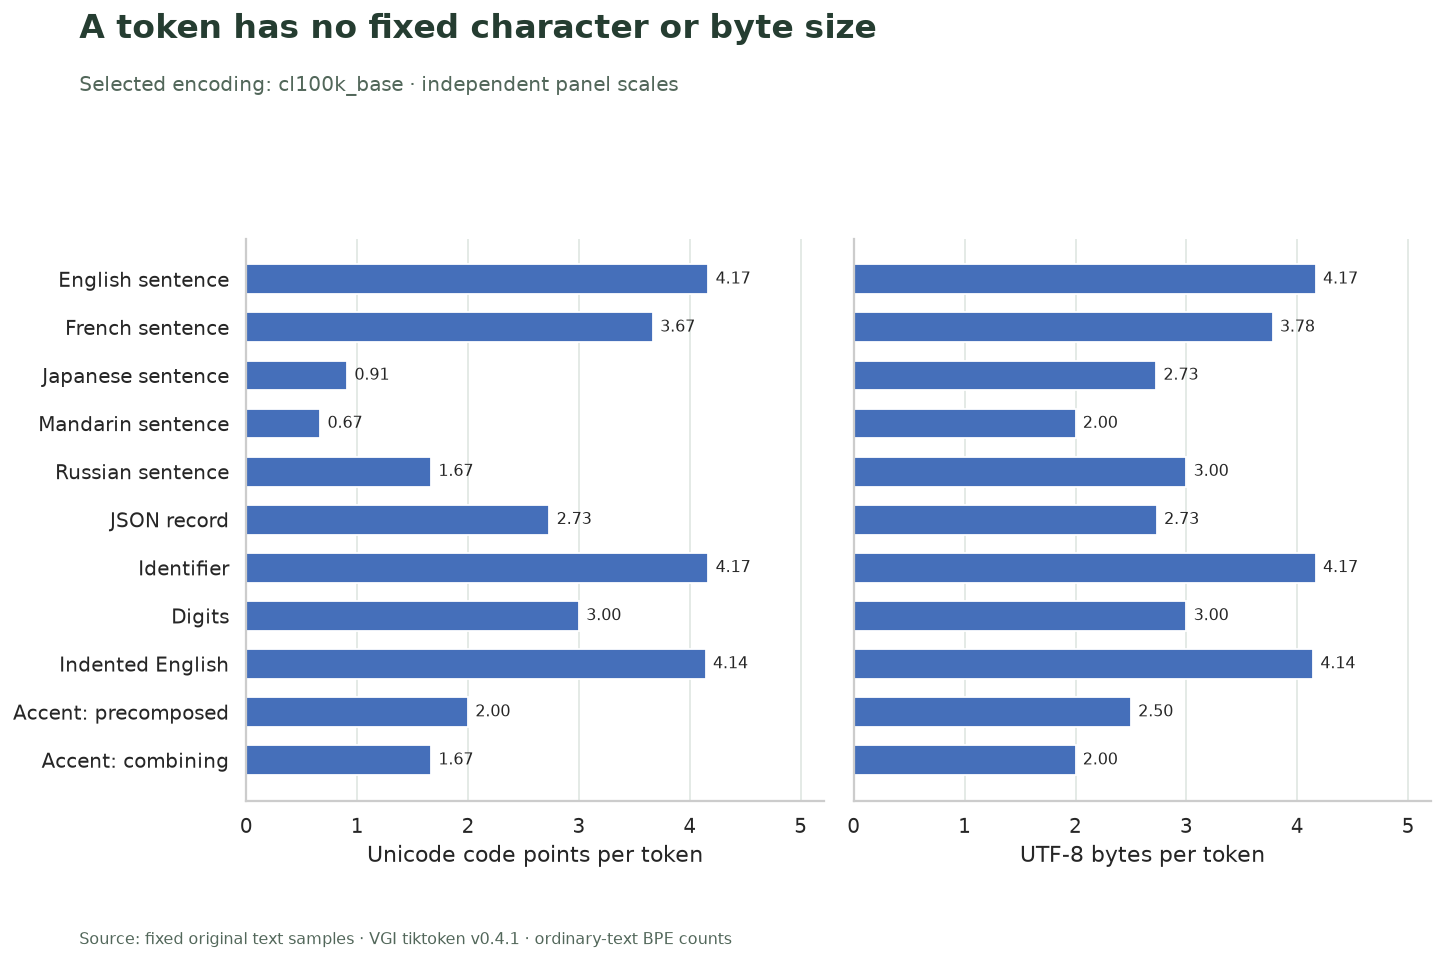

The precomposed accent uses **4 code points / 5 bytes / 2 tokens**; the combining version uses **5 / 6 / 3**. Their appearance is similar, but their underlying representations differ. Normalize only when that transformation fits your data contract.

In [12]:
selected = globals()["selected"]
display(selected)
y = np.arange(len(selected))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 7.5), sharey=True)
for ax, column, label in zip(
    axes,
    ("code_points_per_token", "bytes_per_token"),
    ("Unicode code points per token", "UTF-8 bytes per token"),
    strict=True,
):
    bars = ax.barh(y, selected[column], height=0.62, color=ENCODING_COLORS[ENCODING])
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
    ax.set(xlabel=label, xlim=(0, selected[column].max() * 1.25))
    ax.grid(axis="y", visible=False)
axes[0].set(yticks=y, yticklabels=selected.label)
axes[0].invert_yaxis()
finish(
    fig,
    "A token has no fixed character or byte size",
    f"Selected encoding: {ENCODING} · independent panel scales",
    f"ratios-{ENCODING}.png",
)
accent = selected[selected.sample_id.isin([10, 11])].sort_values("sample_id")
a, b = list(accent.itertuples())
prose(
    f"The precomposed accent uses **{int(a.code_points)} code points / {int(a.utf8_bytes)} bytes / {int(a.token_count)} tokens**; the combining version uses **{int(b.code_points)} / {int(b.utf8_bytes)} / {int(b.token_count)}**. Their appearance is similar, but their underlying representations differ. Normalize only when that transformation fits your data contract."
)

## Token IDs belong to an encoding

Both encodings count `hello world` as two tokens, but the ID lists differ. Store
the encoding alongside token IDs; numeric IDs are vocabulary positions and cannot
be compared across encodings as if they identified the same text fragments.

In [13]:
%%sql
SELECT encoding, tokens.main.tokenize('hello world', encoding) AS token_ids
FROM (VALUES ('cl100k_base'), ('o200k_base')) e(encoding);

,encoding,token_ids
0,cl100k_base,"[15339, 1917]"
1,o200k_base,"[24912, 2375]"


## A token boundary can split a Unicode character

The pinned worker's truncation function decodes retained token bytes with a
**lossy UTF-8 conversion**. It can insert the replacement character `�` if the
cut splits a character. The following control deliberately uses **cl100k_base**
regardless of the selected comparison encoding. The ASCII boundary is readable;
the one-token emoji cut is not a lossless prefix of the original string.

The worker's chunking function uses the same lossy decoding approach. Inspect
boundaries before relying on truncated or chunked text for exact reconstruction.

In [14]:
%%sql boundaries <<
SELECT text AS original, tokens.main.count_tokens(text, 'cl100k_base') AS original_tokens,
       tokens.main.truncate_to_tokens(text, 1, 'cl100k_base') AS retained_text
FROM (VALUES ('hello world'), ('🌍')) t(text);

In [15]:
boundaries = globals()["boundaries"]
display(boundaries)
replaced = boundaries[boundaries.retained_text.str.contains("\ufffd", regex=False)]
prose(
    f"**{len(replaced)} of these {len(boundaries)} boundary controls** contains a replacement character after truncation. Count and retain original token IDs when exact token accounting matters; the reconstructed text can have different bytes from the source."
)

,original,original_tokens,retained_text
0,hello world,2,hello
1,🌍,3,�


**1 of these 2 boundary controls** contains a replacement character after truncation. Count and retain original token IDs when exact token accounting matters; the reconstructed text can have different bytes from the source.

## Experiment: change only the selected encoding

Set **`ENCODING = "o200k_base"`**, restart and run all. Predict which ratios will
move, then compare the detailed table, bar outline and ratio panels. The exact
input strings, code-point/byte lengths and full two-encoding count comparison
must stay the same. The explicit cl100k_base boundary control also stays fixed.
Reset to **`"cl100k_base"`**.

For a real text collection, keep the encoding explicit and measure the original
strings. This notebook establishes ordinary-text counts; application formatting
and complete request usage require their own accounting.

In [16]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)